# Simplified setting: reduced-state, frozen-readout, gauge-free attention

Reduces the ICL Markov-with-noise task (folders 6/10) to a smaller, more theoretically
tractable version, while preserving the properties that make the FFN's finite-sample
count-denoising story visible. Everything is controlled from the **CONFIG cell** below —
change a setting and re-run top to bottom.

| change | folder 10 | here | why it's safe |
|---|---|---|---|
| vocab | V_sig=10, n_noise=10 | **V_sig=4, n_noise=4** | still 2-successors-per-state (sparse prior); *higher* relative sparsity (2/4 vs 2/10) |
| context / loss window | seq_len=200, loss on last 100 | **seq_len=100, loss on last 50** | per-state sample count at window start ≈12.5α (new) vs ≈10α (old, 10 states/200 ctx) — same finite-sample regime |
| successor split | p1~U(0,1) | **p1~U(0.1,0.9)** | avoids near-deterministic states that need no context inference |
| thresholds | 0.1..0.9 | **[0.4,0.5,0.6,0.7,0.8,0.9,1.0]** | drops the too-sparse-signal low end; α=1.0 is a no-noise edge case (qualitatively different — no denoising sub-task at all, kept as an upper-bound sanity check) |
| architecture | separate Wq,Wk,Wv,Wo | **combined W_qk, W_ov** (folder 7 style) | removes the within-head rotation gauge; exact reparametrization, not an approximation |
| trainable params | everything | **W_qk, W_ov (both layers) + fc_out (+bias) only** | isolates "does GD find the right attention circuit" from "does GD find the right readout" |
| FFN | trained | **frozen at a fitted log(f+δ) count-readout**, δ=1 ⇒ exactly the context-Bayes / Beta(1,1) prior | numerically stable (fit + verified below in-notebook), theoretically principled — not copied stale tuned constants |
| optimizer | Adam only | **Adam or SGD**, one switch in CONFIG | vanilla SGD matches the GD-learns-causal-structure theory (Nichani et al. 2024) |
| data | 20k train | **10k train** | plenty given fewer states / shorter context |

**Frozen-readout design.** The FFN (`ff1`,`ff2`) is overwritten with a *fitted*, block-diagonal
GELU construction implementing, independently per signal state `v`, the residual correction
`f_v ↦ f_v + CORE(f_v) ≈ log(f_v + δ)` at coordinate `in2+v` of the hidden state (`in2` = the
offset of layer-2's attention-output block — the same coordinate convention the project's
hand-built W* construction has always used). All other coordinates (incl. the noise block) are
left untouched; the constant noise floor `(1-α)/n_noise` is left for the *trainable* `fc_out.bias`
to absorb directly, no FFN needed for it. `CORE` is fit **once at notebook load** via a
closed-form spline warm-start + a short Adam refinement (see the "frozen-readout fit" cells) — it
is not a hardcoded constant, so it re-derives itself correctly if you change `V_SIG`, `FREEZE_DELTA`,
or anything else.

This gives GD a *fixed, correct* log-count readout for free; the only question left for gradient
descent is whether it can find the attention circuit that feeds count information into the right
coordinate — a much narrower, more tractable question than the joint problem folders 6–10 study.


In [2]:
# ── imports + shared-box temp-dir routing (this box's system /tmp is unusable) ──
import json, os, time, math
import tempfile

_TMP = os.path.join(os.path.expanduser('~'), '.cache', 'ashu_tmp')
os.makedirs(_TMP, exist_ok=True)
for _v in ('TMPDIR', 'TMP', 'TEMP'):
    os.environ[_v] = _TMP
tempfile.tempdir = _TMP
os.environ.setdefault('MPLCONFIGDIR', _TMP)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


In [3]:
# ══════════════════════════════ CONFIG ══════════════════════════════════════
# Every setting the experiment depends on lives here. Change anything and re-run
# top to bottom -- nothing downstream is hardcoded against these values.

# ── task size ────────────────────────────────────────────────────────────────
V_SIG   = 4                      # number of "ruled" (signal) states, each with 2 successors
N_NOISE = 4                      # number of noise tokens
V       = V_SIG + N_NOISE        # total vocab

SEQ_LEN     = 100                # total context length per sequence
TOKEN_START = 50                 # loss / eval window: last (SEQ_LEN - TOKEN_START) tokens
TOKEN_END   = SEQ_LEN

# NOTE: literal list from the spec discussion; the phrasing "removing thresholds < 0.5" was
# inconsistent with keeping 0.4 in the list -- this is the literal list, edit freely.
# alpha=1.0 is a no-noise edge case: qualitatively different (no denoising sub-task at all),
# kept here only as an upper-bound sanity check, not as "just another point on the curve".
THRESHOLDS = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

SUCC_P_LOW, SUCC_P_HIGH = 0.1, 0.9   # per-state successor split p1~U(low,high), p2=1-p1
                                      # (clipped away from 0/1 so every state needs real inference)

# ── data ────────────────────────────────────────────────────────────────────
DATA_DIR  = 'dataset'             # written by data_generation.py -- run that script first
N_TRAIN   = 20_000
N_TEST    = 2_000
# No held-out validation split: trains on the FULL N_TRAIN, checkpoints on best TRAIN loss
# (test loss is still tracked/saved each epoch for monitoring, just not used for selection).
DATA_SEED = 42

# ── architecture ─────────────────────────────────────────────────────────────
ATTN_DIM = V + SEQ_LEN           # = initial_dim, same convention as folders 6/8/10's W*
                                  # (keeps the "frequency lives at in2+v" coordinate valid)
BIAS     = True                  # fc_out bias (needed to absorb the noise floor)

# 'combined' -> W_qk/W_ov (folder 7 style, gauge-free) ; 'separate' -> Wq,Wk,Wv,Wo
# (folders 6/8/10 style, keeps the within-head rotation gauge). Must match whatever a
# checkpoint was actually trained with -- load_trained_model reads it from that
# checkpoint's own metrics json, falling back to this default for old checkpoints.
ATTN_PARAM = 'combined'

# ── frozen log-readout construction ──────────────────────────────────────────
FREEZE_READOUT   = True          # freeze ff1/ff2 at the fitted log(f+delta) count-readout
FREEZE_DELTA     = 1.0           # Laplace / Beta(1,1) smoothing constant
                                  # (=1.0 makes this EXACTLY the context-Bayes prior, see CE plot)
FREEZE_HIDDEN_K  = 128           # GELU hidden units per signal state approximating log(f+delta);
                                  # matches this project's standard mlp_hidden=128 convention
                                  # (folders 6/8/10); raised from 12 for a much tighter fit.
FREEZE_FIT_FMAX  = 40.0          # range over which log(f+delta) is fit (max plausible per-state count)
FREEZE_FIT_STEPS = 2000          # Adam refinement steps after the closed-form spline warm-start

# ── hand-built "in-arch construction" curve (no training at all) ────────────
# Hand-set combined Wqk/Wov induction circuit (folder 10's PerfectInductionTransformer, ported to
# the combined parametrization) + an identity "unembedding" fc_out (bias=True, matching this
# project's fc_out convention) -> raw per-state frequency f -> closed-form readout, NOT the
# Bayes-optimal FREEZE_DELTA=1.0 -- ctx-count-style smoothing is enough here, exposed as its own
# epsilon so it can be tuned independently of the trained model's frozen-readout delta.
CONSTRUCTION_EPS = 0.01

# ── which parameters receive gradients ───────────────────────────────────────
# 'attn'   -> attention params (whichever ATTN_PARAM parametrization is in use)
# 'ffn'    -> ff1, ff2   (ignored / forced-frozen whenever FREEZE_READOUT=True)
# 'fc_out' -> fc_out.weight, fc_out.bias
TRAIN_PARAMS = ['attn', 'fc_out']

# ── optimization ──────────────────────────────────────────────────────────────
OPTIMIZER = 'adam'               # 'adam' or 'sgd' -- flip this one switch
LR = {'adam': 5e-3, 'sgd': 0.1}[OPTIMIZER]   # sane per-optimizer default; override directly if needed
MOMENTUM     = 0.9               # only used when OPTIMIZER='sgd'
WEIGHT_DECAY = 0.0
CLIP_GRAD    = True              # toggle gradient clipping on/off
GRAD_CLIP    = 0.5               # max grad norm, only applied when CLIP_GRAD=True
EPOCHS       = 200
BATCH_SIZE   = 256
PATIENCE     = 60                # early-stop patience (epochs with no train-loss improvement)
EVAL_BATCH   = 256               # mini-batch size for eval forward passes (bounds peak GPU memory
                                  # on a contested shared box -- see CLAUDE.md §6 gotchas)
SEED = 7

# ── misc ──────────────────────────────────────────────────────────────────────
DEVICE     = 'cuda:0'
# Combined and separate parametrizations save to DIFFERENT directories (train.py resolves this
# the same way: models_dir = f"models_{attn_param}") so training one doesn't overwrite the
# other's checkpoints -- both can be loaded and plotted side by side below.
MODELS_DIR_COMBINED = 'models_combined'
MODELS_DIR_SEPARATE = 'models_separate'
os.makedirs(MODELS_DIR_COMBINED, exist_ok=True)
os.makedirs(MODELS_DIR_SEPARATE, exist_ok=True)
# comparison plots (CE-vs-alpha, training curves) span both architectures, so they aren't tied
# to one attn_param -- saved into MODELS_DIR_COMBINED for simplicity.
MODELS_DIR = MODELS_DIR_COMBINED

device = torch.device(DEVICE if torch.cuda.is_available() else 'cpu')
print(f'device={device}   V_sig={V_SIG} n_noise={N_NOISE} V={V}   seq_len={SEQ_LEN}  '
      f'window=[{TOKEN_START}:{TOKEN_END}]')
print(f'thresholds={THRESHOLDS}')
print(f'FREEZE_READOUT={FREEZE_READOUT} (delta={FREEZE_DELTA}, hidden_k={FREEZE_HIDDEN_K}/state)   '
      f'ATTN_PARAM={ATTN_PARAM}   TRAIN_PARAMS={TRAIN_PARAMS}   optimizer={OPTIMIZER} lr={LR}   '
      f'CLIP_GRAD={CLIP_GRAD}')


device=cuda:0   V_sig=4 n_noise=4 V=8   seq_len=100  window=[50:100]
thresholds=[0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
FREEZE_READOUT=True (delta=1.0, hidden_k=128/state)   ATTN_PARAM=combined   TRAIN_PARAMS=['attn', 'fc_out']   optimizer=adam lr=0.005   CLIP_GRAD=True


## All function & class definitions

Everything the rest of the notebook calls lives in the single cell below (data loading, model classes, the frozen log-readout fit, baseline predictors, and checkpoint loading) -- run it once. Every cell after this one is inference/analysis: it only calls these functions, it doesn't define new ones.

In [4]:
# ── Data ──────────────────────────────────────────────────────────────────

def load_data(split, thr, n_cap=None):
    """Load a threshold's pre-generated blob written by data_generation.py. No on-the-fly
    generation -- this notebook trains/evaluates on the EXACT sequences on disk, so results are
    reproducible across runs/kernels without needing to reseed a generator in-notebook."""
    path = os.path.join(DATA_DIR, split, f'data_x_{thr}.pt')
    blob = torch.load(path, weights_only=False)
    if n_cap is not None:
        n = min(n_cap, blob['x'].shape[0])
        blob = dict(blob)
        blob['x'] = blob['x'][:n]; blob['y'] = blob['y'][:n]
        for k in ('transitions', 'trans_probs'):
            if k in blob: blob[k] = blob[k][:n]
    return blob

# ── Model: combined- or separate-QK/OV attention + (frozen) log-readout FFN ─

class CombinedAttentionBlock(nn.Module):
    """QK/OV combined parametrization (folder 7 style, project CLAUDE.md §3):
    scores = x @ W_qk @ x^T ;  out = softmax(scores) @ (x @ W_ov).
    W_qk, W_ov ARE the only free parameters -- this removes the within-head Q/K and V/O
    rotation gauge (exact, not an approximation; folder 7 verified collapsing a hand-built
    W* into this form gives 0.0 logit diff vs the separate-matrix parametrization)."""
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_qk = nn.Parameter(torch.empty(input_dim, input_dim))
        self.W_ov = nn.Parameter(torch.empty(input_dim, output_dim))
        nn.init.xavier_uniform_(self.W_qk)
        nn.init.xavier_uniform_(self.W_ov)

    def forward(self, x, mask=None):
        scores = torch.bmm(x @ self.W_qk, x.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None:
            scores = scores + mask
        attn_out = torch.bmm(F.softmax(scores, dim=-1), x @ self.W_ov)
        return torch.cat([x, attn_out], dim=-1), scores


class SeparateAttentionBlock(nn.Module):
    """Separate Wq,Wk,Wv,Wo parametrization (folders 6/8/10 style). Unlike the combined block,
    this keeps the within-head Q/K and V/O rotation gauge -- Wq,Wk individually free even though
    only WqᵀWk affects the output (same for Wo·Wv). Strictly more parameters than the combined
    form for the same functional capacity; useful for comparing whether GD's solution under the
    two parametrizations differs beyond that gauge freedom."""
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V_ = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None:
            scores = scores + mask
        attn_out = self.W_o(torch.bmm(F.softmax(scores, dim=-1), V_))
        return torch.cat([x, attn_out], dim=-1), scores


_ATTN_BLOCKS = {'combined': CombinedAttentionBlock, 'separate': SeparateAttentionBlock}


class SimplifiedTransformerMLP(nn.Module):
    """Two attention layers (combined W_qk/W_ov OR separate Wq/Wk/Wv/Wo, per attn_param) + a
    position-wise GELU FFN head + linear unembedding. Same skeleton as folders 6/8/10's
    DisentangledTransformerMLP. `in2` marks where layer-2's attention-output block begins in the
    concatenated hidden state -- the same coordinate convention the project's hand-built W*
    construction has always used for "where the frequency counts live"; this is architecture-level
    (concat structure), so it holds regardless of which attention parametrization is chosen."""
    def __init__(self, total_vocab, seq_len, attn_dim, v_sig, ffn_hidden_per_state, bias=True,
                 attn_param='combined'):
        super().__init__()
        self.total_vocab = total_vocab
        self.seq_len      = seq_len
        self.v_sig        = v_sig
        self.attn_param   = attn_param
        self.initial_dim  = total_vocab + seq_len
        Block = _ATTN_BLOCKS[attn_param]
        self.layer1 = Block(self.initial_dim, attn_dim)
        self.layer2 = Block(self.initial_dim + attn_dim, attn_dim)
        self.D   = self.initial_dim + 2 * attn_dim
        self.in2 = self.initial_dim + attn_dim
        self.ff1 = nn.Linear(self.D, v_sig * ffn_hidden_per_state)
        self.ff2 = nn.Linear(v_sig * ffn_hidden_per_state, self.D)
        self.act = nn.GELU()
        self.fc_out = nn.Linear(self.D, total_vocab, bias=bias)

    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, _ = self.layer1(s, mask)
        s, _ = self.layer2(s, mask)
        s = s + self.ff2(self.act(self.ff1(s)))
        return self.fc_out(s)

# ── Frozen log-readout: fit + install ────────────────────────────────────

def fit_log_core(delta=FREEZE_DELTA, k=FREEZE_HIDDEN_K, fmax=FREEZE_FIT_FMAX,
                  steps=FREEZE_FIT_STEPS, device='cpu', seed=0):
    torch.manual_seed(seed)
    f = torch.linspace(0, fmax, 400, device=device).unsqueeze(1)          # [N,1]
    target = torch.log(f + delta) - f                                    # [N,1]

    # closed-form spline warm-start: spread GELU breakpoints evenly over [0,fmax],
    # then solve for (w,c) via linear least squares with (a,b) held fixed.
    breakpoints = torch.linspace(0, fmax, k, device=device)
    a0 = torch.full((1, k), 6.0 / max(fmax, 1e-6), device=device)
    b0 = (-a0.squeeze(0) * breakpoints).unsqueeze(0)
    a = nn.Parameter(a0.clone()); b = nn.Parameter(b0.clone())
    with torch.no_grad():
        basis  = F.gelu(f * a + b)
        basis1 = torch.cat([basis, torch.ones(basis.shape[0], 1, device=device)], dim=1)
        sol    = torch.linalg.lstsq(basis1, target).solution
        w0, c0 = sol[:k], sol[k:k + 1].squeeze(0)
    w = nn.Parameter(w0.clone()); c = nn.Parameter(c0.clone())

    opt = torch.optim.Adam([a, b, w, c], lr=1e-2)
    for _ in range(steps):
        opt.zero_grad()
        pred = F.gelu(f * a + b) @ w + c
        loss = F.mse_loss(pred, target)
        loss.backward(); opt.step()
    return a.detach(), b.detach(), w.detach(), c.detach(), float(loss.item())


def build_frozen_ffn(model, delta=FREEZE_DELTA, k=FREEZE_HIDDEN_K, fmax=FREEZE_FIT_FMAX,
                      steps=FREEZE_FIT_STEPS):
    dev = next(model.parameters()).device
    a, b, w, c, mse = fit_log_core(delta, k, fmax, steps, device=dev)
    Vs, D, in2 = model.v_sig, model.D, model.in2
    W1 = torch.zeros(Vs * k, D, device=dev); B1 = torch.zeros(Vs * k, device=dev)
    W2 = torch.zeros(D, Vs * k, device=dev); B2 = torch.zeros(D, device=dev)
    for v in range(Vs):
        rows = slice(v * k, (v + 1) * k)
        W1[rows, in2 + v] = a.squeeze(0)
        B1[rows]          = b.squeeze(0)
        W2[in2 + v, rows] = w.squeeze(1)
        B2[in2 + v]       = c
    with torch.no_grad():
        model.ff1.weight.copy_(W1); model.ff1.bias.copy_(B1)
        model.ff2.weight.copy_(W2); model.ff2.bias.copy_(B2)
    for p in (model.ff1.weight, model.ff1.bias, model.ff2.weight, model.ff2.bias):
        p.requires_grad_(False)
    print(f'[frozen readout] fit MSE={mse:.2e}  over f in [0,{fmax}]  (delta={delta}, '
          f'K={k}/state, {Vs} states)')
    return mse

# ── Baseline predictors (no training) ────────────────────────────────────

def ideal_alpha_dist(blob, alpha):
    x_np = blob['x'].numpy(); trans = blob['transitions']; probs = blob['trans_probs']
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_arr = np.array([[trans[b][v] for v in range(Vs)] for b in range(B)], dtype=np.int64)
    prob_arr  = np.array([[probs[b][v] for v in range(Vs)] for b in range(B)], dtype=np.float64)
    p_win = np.zeros((B, W, V_), dtype=np.float64)
    last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < Vs
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        s0 = trans_arr[np.arange(B), last_sig, 0]; s1 = trans_arr[np.arange(B), last_sig, 1]
        q0 = prob_arr[np.arange(B), last_sig, 0];  q1 = prob_arr[np.arange(B), last_sig, 1]
        p = np.zeros((B, V_), dtype=np.float64)
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p[np.arange(B), s0] += alpha * q0
        p[np.arange(B), s1] += alpha * q1
        p_win[:, t - TOKEN_START] = p
    return p_win

def context_bayes_dist(blob, alpha, eps=FREEZE_DELTA):
    """Laplace/Beta(1,1)-smoothed counts. eps=FREEZE_DELTA by default so this exactly matches
    what the frozen FFN targets (delta=1 <=> Beta(1,1) prior) -- the natural comparison point
    for the trained model."""
    x_np = blob['x'].numpy()
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts = np.zeros((B, V_, Vs), dtype=np.float64)
    pending      = np.zeros((B, V_), dtype=np.float64)
    last_ruled   = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok = x_np[:, col]; is_sig = tok < Vs
        ri = np.where(is_sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(Vs) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_sig)[0]
        if len(ni): pending[ni, tok[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    p_win = np.zeros((B, W, V_), dtype=np.float64)
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]; is_sig_q = v < Vs
        q   = np.where(is_sig_q, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), q] + eps
        tot = cnt.sum(axis=1, keepdims=True)
        p = np.zeros((B, V_), dtype=np.float64)
        p[:, :Vs] = cnt / tot * alpha
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        _step(t)
    return p_win

def ctx_count_dist(blob, alpha, eps=0.01):
    return context_bayes_dist(blob, alpha, eps=eps)   # identical estimator, smaller smoothing eps

def _ce_from_win(p_win, y_np):
    yw = y_np[:, TOKEN_START:TOKEN_END]; B, W = yw.shape
    bb = np.arange(B)[:, None]; ww = np.arange(W)[None, :]
    return float((-np.log(np.maximum(p_win[bb, ww, yw], 1e-12))).mean())

# ── Hand-built "in-arch construction" (no training at all) ────────────────
def _build_construction_attn(V, T, Vs, dev):
    """Hand-set combined Wqk/Wov weights implementing the EXACT induction circuit from folder
    10's PerfectInductionTransformer (generic in V,T,Vs -- identical constants, just algebraically
    converted from that separate-matrix form via W_qk = Wq^T@Wk, W_ov = Wv^T@Wo^T, the same exact
    reparametrization CLAUDE.md §3 already verified gives 0.0 logit diff vs the separate form)."""
    D = V + T
    # -- layer 1 (separate form, exactly as folder 10's W*) --
    Wq1 = torch.eye(D, device=dev) * (D ** 0.5)
    T1 = torch.zeros(D, D, device=dev)
    for k in range(Vs, V): T1[k, :] = -1e9
    for tq in range(T):
        for tk in range(T):
            T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
    Wk1 = T1.t()
    Wv1 = torch.zeros(D, D, device=dev); Wv1[:V, :V] = torch.eye(V, device=dev)
    Wo1 = torch.eye(D, device=dev)
    Wqk1 = Wq1.t() @ Wk1
    Wov1 = Wv1.t() @ Wo1.t()

    # -- layer 2 (separate form, exactly as folder 10's W*) --
    in2 = D + D
    Wq2 = torch.zeros(D, in2, device=dev)
    Wq2[:Vs, :Vs]    = torch.eye(Vs, device=dev) * (D ** 0.5) * 1000.0
    Wq2[:Vs, D:D+Vs] = torch.eye(Vs, device=dev) * (D ** 0.5) * 50.0
    for v in range(V): Wq2[Vs, v] = (D ** 0.5) * 10.0
    Wk2 = torch.zeros(D, in2, device=dev); Wk2[:V, D:D+V] = torch.eye(V, device=dev)
    for v in range(Vs, V): Wk2[Vs, v] = -50000.0
    Wv2 = torch.zeros(D, in2, device=dev); Wv2[:V, :V] = torch.eye(V, device=dev)
    Wo2 = torch.eye(D, device=dev)
    Wqk2 = Wq2.t() @ Wk2
    Wov2 = Wv2.t() @ Wo2.t()
    return Wqk1, Wov1, Wqk2, Wov2


_CONSTRUCTION_CACHE = {}

def build_construction_model(V, T, Vs, dev):
    """Build a SimplifiedTransformerMLP(attn_param='combined') with the hand-set induction
    circuit above, a DORMANT FFN (ff2 zeroed -> residual contributes nothing), and an identity
    unembedding fc_out (bias=True, matching this project's fc_out convention) that copies the
    raw per-state frequency straight into logit space. The closed-form readout in
    construction_dist then turns those raw counts into probabilities -- exactly like
    ctx_count_dist does, just fed by an actual attention circuit instead of a numpy count loop."""
    attn_dim = V + T
    m = SimplifiedTransformerMLP(V, T, attn_dim, Vs, FREEZE_HIDDEN_K, bias=True,
                                  attn_param='combined').to(dev)
    Wqk1, Wov1, Wqk2, Wov2 = _build_construction_attn(V, T, Vs, dev)
    with torch.no_grad():
        m.layer1.W_qk.copy_(Wqk1); m.layer1.W_ov.copy_(Wov1)
        m.layer2.W_qk.copy_(Wqk2); m.layer2.W_ov.copy_(Wov2)
        m.ff2.weight.zero_(); m.ff2.bias.zero_()          # dormant FFN
        m.fc_out.weight.zero_()
        m.fc_out.weight[:V, m.in2:m.in2 + V] = torch.eye(V, device=dev)   # identity selector
        m.fc_out.bias.zero_()
    for p in m.parameters(): p.requires_grad_(False)
    m.eval()
    return m


@torch.no_grad()
def construction_dist(blob, alpha, eps=CONSTRUCTION_EPS, dev=None):
    """Hand-built combined-Wqk/Wov induction circuit + identity unembedding (bias) -> raw
    per-state frequency f -> CLOSED-FORM ctx-count-style readout alpha*(f+eps)/sum(f+eps) for
    signal, exact noise floor for noise. Deliberately NOT the Bayes-optimal delta=1 -- see
    CONSTRUCTION_EPS in the CONFIG cell. `dev` lets baseline-computation cells force CPU to avoid
    a contended shared GPU -- this model is tiny (attn_dim~108) so CPU is plenty fast for it."""
    dev = dev or device
    V = blob['total_vocab']; Vs = blob['vocab_set1']; seq_len = blob['seq_len']
    key = (V, seq_len, Vs, str(dev))
    m = _CONSTRUCTION_CACHE.get(key)
    if m is None:
        m = build_construction_model(V, seq_len, Vs, dev)
        _CONSTRUCTION_CACHE[key] = m
    logits = m(blob['x'].to(dev))[:, TOKEN_START:TOKEN_END]
    f = logits[..., :Vs].clamp_min(0.0)
    psig = alpha * (f + eps) / (f + eps).sum(-1, keepdim=True)
    pn = (1.0 - alpha) / (V - Vs)
    pnoise = torch.full(psig.shape[:-1] + (V - Vs,), pn, device=psig.device)
    return torch.cat([psig, pnoise], dim=-1).cpu().numpy()


# ── Analysis-time tooling ─────────────────────────────────────────────────

@torch.no_grad()
def eval_ce(model, x, y, batch=EVAL_BATCH):
    model.eval()
    total_nll, total_n = 0.0, 0
    for i in range(0, x.shape[0], batch):
        xb = x[i:i + batch].to(device)
        yb = y[i:i + batch, TOKEN_START:TOKEN_END].to(device)
        logits = model(xb)[:, TOKEN_START:TOKEN_END]
        loss = F.cross_entropy(logits.reshape(-1, V), yb.reshape(-1), reduction='sum')
        total_nll += loss.item(); total_n += yb.numel()
        del xb, yb, logits, loss
        if device.type == 'cuda': torch.cuda.empty_cache()
    model.train()
    return total_nll / total_n

# ── Load a trained checkpoint (train.py's output) ────────────────────────

def load_trained_model(thr, models_dir, tag=None):
    """Build a fresh SimplifiedTransformerMLP and load the checkpoint train.py wrote for this
    threshold from `models_dir` (pass MODELS_DIR_COMBINED or MODELS_DIR_SEPARATE -- train.py
    saves each attn_param to its own directory so the two never overwrite each other). Returns
    (model, metrics_dict) or (None, None) if train.py hasn't reached this threshold yet.
    attn_param AND freeze_hidden_k are both read from the checkpoint's OWN saved config (falling
    back to this notebook's current CONFIG only for older checkpoints missing those fields) --
    a checkpoint's ff1/ff2 shape is baked in at whatever FREEZE_HIDDEN_K was set when it was
    trained, so if this notebook's FREEZE_HIDDEN_K is later changed (e.g. 12 -> 128), reusing the
    NEW value here would build the wrong-shaped model and crash on load_state_dict."""
    tag = tag or f'simplified_{OPTIMIZER}'
    mp = os.path.join(models_dir, f'model_{tag}_x_{thr}.pth')
    cp = os.path.join(models_dir, f'metrics_{tag}_x_{thr}.json')
    if not os.path.exists(mp):
        return None, None
    metrics = json.load(open(cp)) if os.path.exists(cp) else None
    cfg = (metrics or {}).get('config', {})
    attn_param      = cfg.get('attn_param', ATTN_PARAM)
    freeze_hidden_k = cfg.get('freeze_hidden_k', FREEZE_HIDDEN_K)
    model = SimplifiedTransformerMLP(V, SEQ_LEN, ATTN_DIM, V_SIG, freeze_hidden_k, bias=BIAS,
                                      attn_param=attn_param).to(device)
    model.load_state_dict(torch.load(mp, map_location=device, weights_only=True))
    model.eval()
    return model, metrics


## Verify the frozen log-readout fit quality

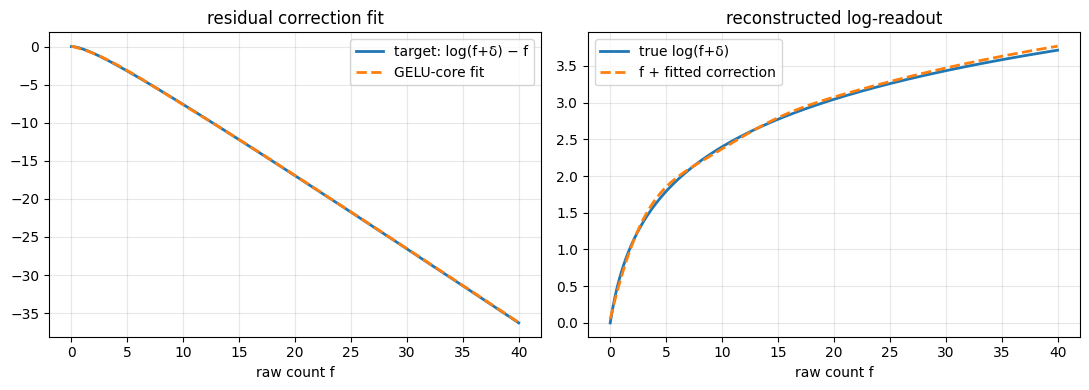

fit MSE=7.13e-04   max |error|=0.0643   mean |error|=0.0335
If this is too loose, raise FREEZE_HIDDEN_K and/or FREEZE_FIT_STEPS in the CONFIG cell.


In [7]:
# ── verify the fit quality before trusting it ────────────────────────────────
if FREEZE_READOUT:
    _a, _b, _w, _c, _mse = fit_log_core()
    _f = torch.linspace(0, FREEZE_FIT_FMAX, 400).unsqueeze(1)
    _target = torch.log(_f + FREEZE_DELTA) - _f
    _pred = F.gelu(_f * _a + _b) @ _w + _c
    _recon = (_pred + _f).squeeze(-1); _true = torch.log(_f + FREEZE_DELTA).squeeze(-1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(_f.numpy(), _target.numpy(), lw=2, label='target: log(f+δ) − f')
    axes[0].plot(_f.numpy(), _pred.detach().numpy(), '--', lw=2, label='GELU-core fit')
    axes[0].set_xlabel('raw count f'); axes[0].set_title('residual correction fit')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(_f.numpy(), _true.numpy(), lw=2, label='true log(f+δ)')
    axes[1].plot(_f.numpy(), _recon.detach().numpy(), '--', lw=2, label='f + fitted correction')
    axes[1].set_xlabel('raw count f'); axes[1].set_title('reconstructed log-readout')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    _err = (_recon - _true).abs()
    print(f'fit MSE={_mse:.2e}   max |error|={_err.max().item():.4f}   mean |error|={_err.mean().item():.4f}')
    print('If this is too loose, raise FREEZE_HIDDEN_K and/or FREEZE_FIT_STEPS in the CONFIG cell.')


## Load trained checkpoints (train.py's output) + build `results`

Training runs in **`train.py`**, not in this notebook -- see its own header docstring for the tmux workflow. This cell just loads whatever checkpoints exist in `MODELS_DIR` right now.

In [5]:
def _load_results(models_dir, label, tag=None):
    """Read each threshold's metrics json directly -- NO torch.load / model construction, since
    the plots below only need the scalar best_train/test_at_best and the per-epoch history, all
    of which train.py already saved. Loading the actual .pth weights (500K+ params) just to read
    two numbers was pure wasted compute; use load_trained_model() separately (defined above) if
    a future analysis cell actually needs a live model to run inference through."""
    tag = tag or f'simplified_{OPTIMIZER}'
    res = {}
    for thr in THRESHOLDS:
        cp = os.path.join(models_dir, f'metrics_{tag}_x_{thr}.json')
        if not os.path.exists(cp):
            continue
        metrics = json.load(open(cp))
        res[thr] = dict(history=metrics['history'], best_train=metrics['best_train'],
                         test_at_best=metrics['test_at_best'])
        print(f'  [{label}] thr={thr}  best_train={metrics["best_train"]:.4f}  '
              f'test_at_best={metrics["test_at_best"]:.4f}  '
              f'epochs_run={metrics.get("epochs_run", len(metrics["history"]["test_loss"]))}')
    print(f'  [{label}] {len(res)}/{len(THRESHOLDS)} thresholds loaded\n')
    return res

results_combined = _load_results(MODELS_DIR_COMBINED, 'combined')
results_separate = _load_results(MODELS_DIR_SEPARATE, 'separate')

if not results_combined and not results_separate:
    print('No checkpoints found in either models_combined/ or models_separate/ -- run train.py first.')
elif not results_separate:
    print('No separate-parametrization checkpoints yet -- train.py with attn_param="separate" '
          'to populate models_separate/. The plots below will just show the combined curve until then.')


  [combined] thr=0.4  best_train=1.8522  test_at_best=1.8787  epochs_run=100
  [combined] thr=0.5  best_train=1.7688  test_at_best=1.7916  epochs_run=100
  [combined] thr=0.6  best_train=1.6621  test_at_best=1.6804  epochs_run=100
  [combined] thr=0.7  best_train=1.4852  test_at_best=1.5016  epochs_run=100
  [combined] thr=0.8  best_train=1.3089  test_at_best=1.3239  epochs_run=100
  [combined] thr=0.9  best_train=1.0194  test_at_best=1.0303  epochs_run=100
  [combined] thr=1.0  best_train=0.6009  test_at_best=0.6096  epochs_run=100
  [combined] 7/7 thresholds loaded

  [separate] thr=0.4  best_train=1.7772  test_at_best=1.7902  epochs_run=100
  [separate] thr=0.5  best_train=1.7057  test_at_best=1.7190  epochs_run=100
  [separate] thr=0.6  best_train=1.6049  test_at_best=1.6156  epochs_run=100
  [separate] thr=0.7  best_train=1.4591  test_at_best=1.4757  epochs_run=100
  [separate] thr=0.8  best_train=1.2670  test_at_best=1.2744  epochs_run=100
  [separate] thr=0.9  best_train=1.0093 

## Plots: CE vs α, and training curves

No valid baseline cache found (or THRESHOLDS/CONSTRUCTION_EPS/BASELINE_SPLIT changed) -- computing on split='train'...
Cached baselines -> models_combined/baseline_ce_cache.json


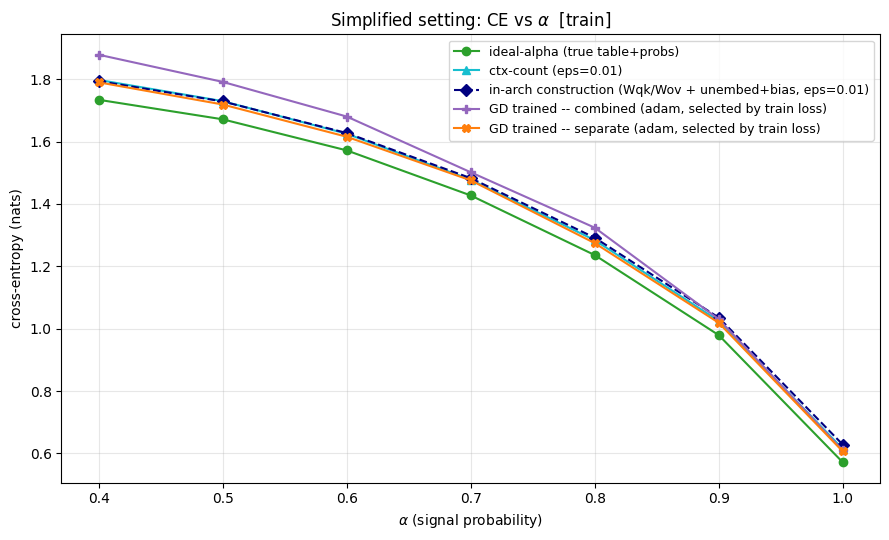

 alpha     ideal       ctx    constr   GD-comb    GD-sep
  0.40    1.7342    1.7979    1.7941    1.8787    1.7902
  0.50    1.6715    1.7298    1.7288    1.7916    1.7190
  0.60    1.5719    1.6252    1.6275    1.6804    1.6156
  0.70    1.4273    1.4778    1.4828    1.5016    1.4757
  0.80    1.2360    1.2838    1.2917    1.3239    1.2744
  0.90    0.9792    1.0248    1.0354    1.0303    1.0188
  1.00    0.5712    0.6144    0.6280    0.6096    0.6061


In [6]:
# Baselines (ideal-alpha, ctx-count, in-arch construction) are cached to disk -- they're never
# computed/saved by train.py, so without a cache every run recomputes them from scratch.
# construction_dist is forced onto CPU (this box's shared GPUs are frequently near-saturated by
# other users -- CLAUDE.md §6) AND run in chunks of BASELINE_BATCH rows -- it's an actual neural
# net forward pass, so switching BASELINE_SPLIT to 'train' (20k rows/threshold) instead of 'test'
# (2k) would otherwise materialize the whole split at once and OOM. ideal_alpha_dist/ctx_count_dist
# are pure numpy (no model), so they're cheap regardless of split size and don't need chunking.

# ── EDIT HERE ──────────────────────────────────────────────────────────────
BASELINE_SPLIT = 'train'    # 'test' (2k rows) or 'train' (20k rows) -- both safe now
BASELINE_BATCH = 256       # rows per chunk for construction_dist, bounds peak memory
# ─────────────────────────────────────────────────────────────────────────

_BASELINE_DEV = torch.device('cpu')
_baseline_cache_path = os.path.join(MODELS_DIR, 'baseline_ce_cache.json')

def _construction_ce_batched(blob, alpha, eps, dev, batch=BASELINE_BATCH):
    """Same result as _ce_from_win(construction_dist(blob, ...), ...), but processes blob['x'] in
    chunks and accumulates the exact NLL sum + count across chunks -- mathematically identical to
    running it on the full blob at once, just bounded in peak memory."""
    x_all, y_all = blob['x'], blob['y']
    n = x_all.shape[0]
    total_nll, total_n = 0.0, 0
    for i in range(0, n, batch):
        sub = dict(blob); sub['x'] = x_all[i:i + batch]; sub['y'] = y_all[i:i + batch]
        p_win = construction_dist(sub, alpha, eps=eps, dev=dev)
        yw = sub['y'].numpy()[:, TOKEN_START:TOKEN_END]
        b, w = yw.shape
        bb = np.arange(b)[:, None]; ww = np.arange(w)[None, :]
        total_nll += -np.log(np.maximum(p_win[bb, ww, yw], 1e-12)).sum()
        total_n += b * w
    return total_nll / total_n

_cache = None
if os.path.exists(_baseline_cache_path):
    _c = json.load(open(_baseline_cache_path))
    if (_c.get('thresholds') == THRESHOLDS and _c.get('construction_eps') == CONSTRUCTION_EPS
            and _c.get('split') == BASELINE_SPLIT):
        _cache = _c
        print(f'Loaded cached baselines from {_baseline_cache_path} (thresholds, '
              f'CONSTRUCTION_EPS, split unchanged) -- skipping recomputation.')

if _cache is None:
    print(f'No valid baseline cache found (or THRESHOLDS/CONSTRUCTION_EPS/BASELINE_SPLIT changed) '
          f'-- computing on split={BASELINE_SPLIT!r}...')
    ideal_ce, ctx_ce, construction_ce = [], [], []
    for thr in THRESHOLDS:
        blob = load_data(BASELINE_SPLIT, thr)
        y_np = blob['y'].numpy()
        ideal_ce.append(_ce_from_win(ideal_alpha_dist(blob, thr), y_np))
        ctx_ce.append(_ce_from_win(ctx_count_dist(blob, thr), y_np))
        construction_ce.append(
            _construction_ce_batched(blob, thr, CONSTRUCTION_EPS, _BASELINE_DEV))
    _cache = {'thresholds': THRESHOLDS, 'construction_eps': CONSTRUCTION_EPS, 'split': BASELINE_SPLIT,
              'ideal_ce': ideal_ce, 'ctx_ce': ctx_ce, 'construction_ce': construction_ce}
    json.dump(_cache, open(_baseline_cache_path, 'w'), indent=2)
    print(f'Cached baselines -> {_baseline_cache_path}')

ideal_ce, ctx_ce, construction_ce = _cache['ideal_ce'], _cache['ctx_ce'], _cache['construction_ce']

# GD curves: only plot thresholds that actually have a loaded checkpoint for that architecture --
# results_combined / results_separate may be partial (or results_separate empty if you haven't
# trained that architecture yet).
combined_thrs  = [t for t in THRESHOLDS if t in results_combined]
combined_ce    = [results_combined[t]['test_at_best'] for t in combined_thrs]
separate_thrs  = [t for t in THRESHOLDS if t in results_separate]
separate_ce    = [results_separate[t]['test_at_best'] for t in separate_thrs]

plt.figure(figsize=(9, 5.5))
plt.plot(THRESHOLDS, ideal_ce, 'o-', color='tab:green', label='ideal-alpha (true table+probs)')
plt.plot(THRESHOLDS, ctx_ce,   '^-', color='tab:cyan',  label='ctx-count (eps=0.01)')
plt.plot(THRESHOLDS, construction_ce, 'D--', color='navy',
         label=f'in-arch construction (Wqk/Wov + unembed+bias, eps={CONSTRUCTION_EPS})')
if combined_thrs:
    plt.plot(combined_thrs, combined_ce, 'P-', color='tab:purple',
              label=f'GD trained -- combined ({OPTIMIZER}, selected by train loss)')
if separate_thrs:
    plt.plot(separate_thrs, separate_ce, 'X-', color='tab:orange',
              label=f'GD trained -- separate ({OPTIMIZER}, selected by train loss)')

plt.xlabel(r'$\alpha$ (signal probability)'); plt.ylabel('cross-entropy (nats)')
plt.title(f'Simplified setting: CE vs $\\alpha$  [{BASELINE_SPLIT}]')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'ce_vs_alpha_simplified.png'), dpi=130)
plt.show()

print(f'{"alpha":>6}  {"ideal":>8}  {"ctx":>8}  {"constr":>8}  {"GD-comb":>8}  {"GD-sep":>8}')
for i, thr in enumerate(THRESHOLDS):
    gd_c = f'{results_combined[thr]["test_at_best"]:8.4f}' if thr in results_combined else '     n/a'
    gd_s = f'{results_separate[thr]["test_at_best"]:8.4f}' if thr in results_separate else '     n/a'
    print(f'{thr:6.2f}  {ideal_ce[i]:8.4f}  {ctx_ce[i]:8.4f}  '
          f'{construction_ce[i]:8.4f}  {gd_c}  {gd_s}')


## on test: 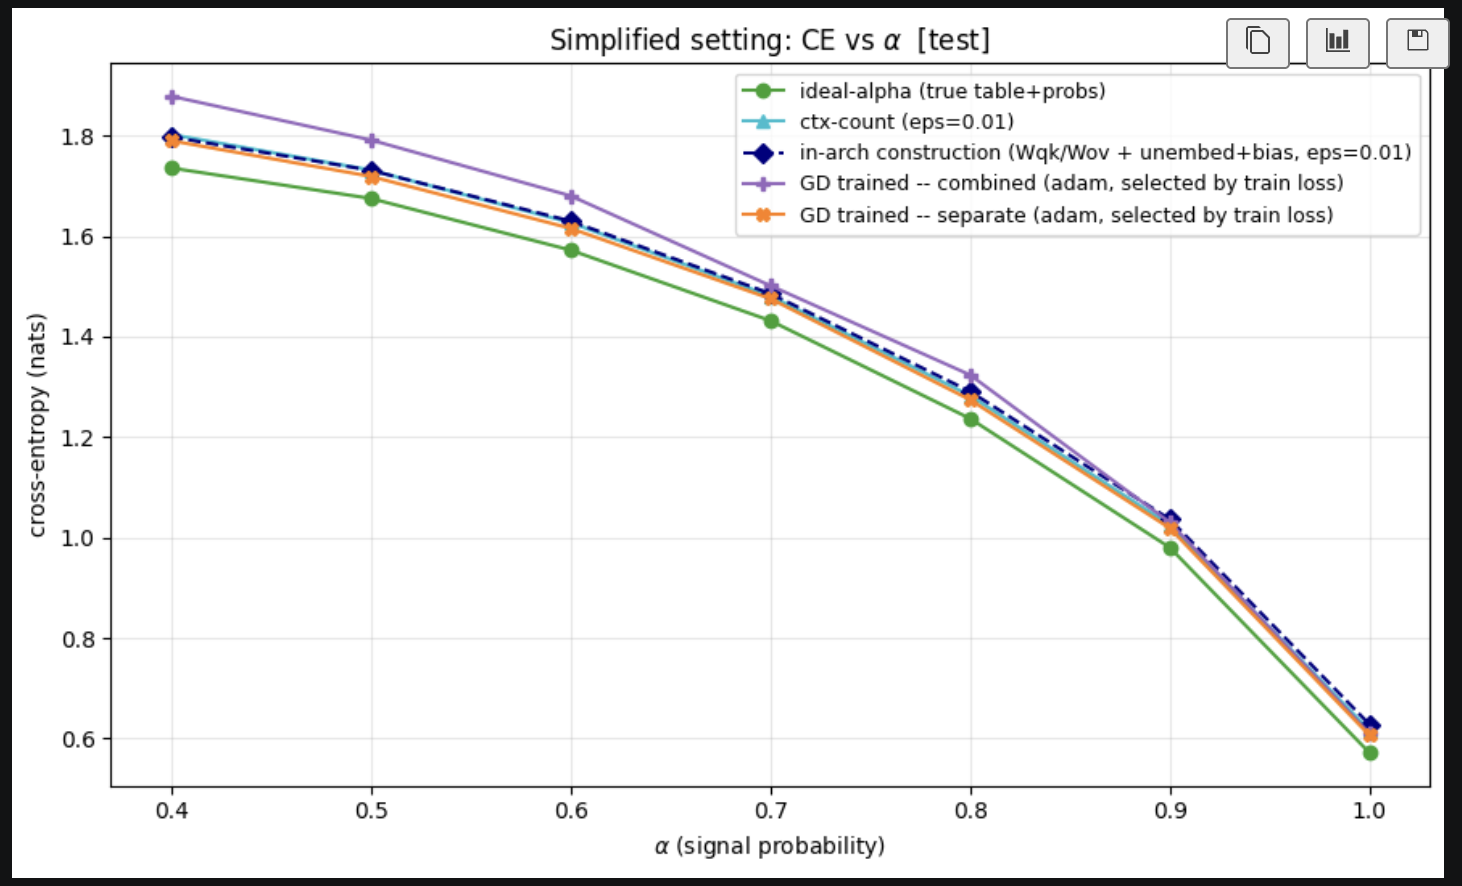

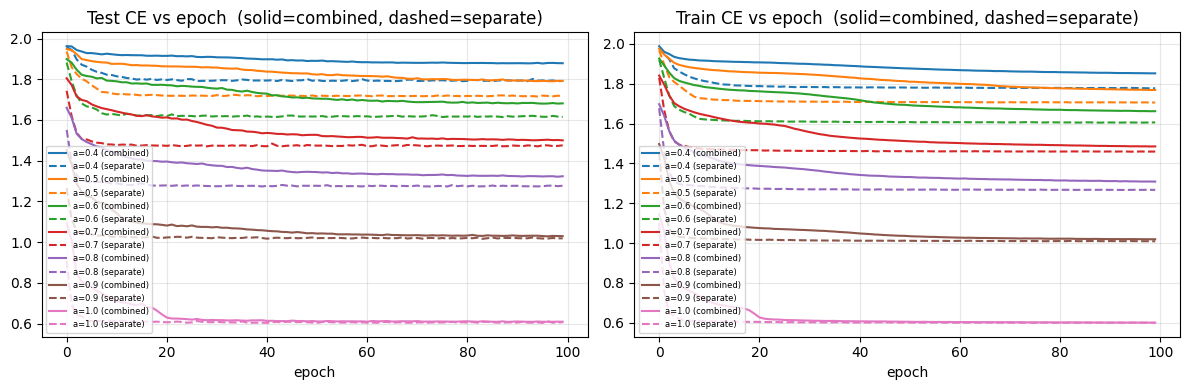

In [6]:
colors = {thr: plt.cm.tab10(i % 10) for i, thr in enumerate(THRESHOLDS)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for thr in THRESHOLDS:
    if thr in results_combined:
        h = results_combined[thr]['history']
        axes[0].plot(h['test_loss'],  color=colors[thr], linestyle='-',  label=f'a={thr} (combined)')
        axes[1].plot(h['train_loss'], color=colors[thr], linestyle='-',  label=f'a={thr} (combined)')
    if thr in results_separate:
        h = results_separate[thr]['history']
        axes[0].plot(h['test_loss'],  color=colors[thr], linestyle='--', label=f'a={thr} (separate)')
        axes[1].plot(h['train_loss'], color=colors[thr], linestyle='--', label=f'a={thr} (separate)')
axes[0].set_title('Test CE vs epoch  (solid=combined, dashed=separate)'); axes[0].set_xlabel('epoch')
axes[1].set_title('Train CE vs epoch  (solid=combined, dashed=separate)'); axes[1].set_xlabel('epoch')
for ax in axes:
    ax.legend(fontsize=6); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'training_curves_simplified.png'), dpi=150)
plt.show()


### Modificaitons: 

- have same matrix inits.   
- plot loss beofore first update as well.
- increase train points to 25k.
- increase test points to 3k.
- train for 400 epochs(lr: 0.005, patience = 30) keep rest setting same.

## Combined vs separate: did GD learn the same attention circuit?

Raw `Wq,Wk,Wv,Wo` from the separate-parametrization model can't be compared to the
combined model's `W_qk,W_ov` directly -- they live under different internal gauges (the
separate form has an extra within-head rotation freedom that doesn't affect the output).
The gauge-free, apples-to-apples comparison is to **collapse** the separate weights into
the same combined form GD found directly: `W_qk = Wq^T @ Wk`, `W_ov = Wv^T @ Wo^T` (the exact
same identity used to build the hand-built "in-arch construction" curve above, and the same
one this project already verified gives 0.0 logit diff between the two parametrizations).

Two independent checks below: **structural** (cosine similarity of the collapsed weight
matrices) and **functional** (do the two models' attention patterns actually agree on real
data, independent of the weights looking similar or not).

In [7]:
# ── EDIT HERE ──────────────────────────────────────────────────────────────
CMP_THRESHOLDS = None    # None -> every threshold present in BOTH results_combined/results_separate
CMP_N          = 300     # #sequences for the functional (attention-pattern) check
# ─────────────────────────────────────────────────────────────────────────

def _collapse_separate(block):
    """SeparateAttentionBlock -> (W_qk, W_ov) in the SAME gauge CombinedAttentionBlock uses.
    Q = x@Wq.weight^T, K = x@Wk.weight^T => scores = x @ (Wq.weight^T @ Wk.weight) @ x^T.
    attn_out = softmax(scores) @ (x@Wv.weight^T) @ Wo.weight^T
             = softmax(scores) @ (x @ (Wv.weight^T @ Wo.weight^T))."""
    W_qk = block.W_q.weight.data.t() @ block.W_k.weight.data
    W_ov = block.W_v.weight.data.t() @ block.W_o.weight.data.t()
    return W_qk, W_ov

def _cos(a, b):
    a = a.flatten().double(); b = b.flatten().double()
    return (a @ b / (a.norm() * b.norm() + 1e-12)).item()

@torch.no_grad()
def _get_attn_patterns(model, x):
    """Replicate SimplifiedTransformerMLP.forward up through each attention layer, capturing the
    POST-SOFTMAX attention pattern at layer1/layer2 -- forward() itself discards these (keeps
    only the final logits), so this is needed for the functional check below."""
    B, T = x.shape
    tok = F.one_hot(x, num_classes=model.total_vocab).float()
    pos = F.one_hot(torch.arange(T, device=x.device),
                     num_classes=model.seq_len).float().unsqueeze(0).expand(B, T, -1)
    s = torch.cat([tok, pos], dim=-1)
    mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
    s1, scores1 = model.layer1(s, mask)
    s2, scores2 = model.layer2(s1, mask)
    return F.softmax(scores1, dim=-1), F.softmax(scores2, dim=-1)

def _attn_agreement(a1, a2):
    """a1, a2: [B,T,T] post-softmax attention. Returns (argmax-agreement rate, mean JSD)."""
    agree = (a1.argmax(-1) == a2.argmax(-1)).float().mean().item()
    eps = 1e-12
    m = 0.5 * (a1 + a2)
    kl1 = (a1 * ((a1 + eps).log() - (m + eps).log())).sum(-1)
    kl2 = (a2 * ((a2 + eps).log() - (m + eps).log())).sum(-1)
    jsd = (0.5 * kl1 + 0.5 * kl2).mean().item()
    return agree, jsd

cmp_thrs = CMP_THRESHOLDS or [t for t in THRESHOLDS if t in results_combined and t in results_separate]
print(f'Comparing combined vs separate for thresholds: {cmp_thrs}\n')

rows = []
for thr in cmp_thrs:
    m_comb, _ = load_trained_model(thr, MODELS_DIR_COMBINED)
    m_sep,  _ = load_trained_model(thr, MODELS_DIR_SEPARATE)
    if m_comb is None or m_sep is None:
        print(f'  [skip] thr={thr}: missing a checkpoint for one architecture'); continue

    # -- structural: cosine similarity of the collapsed weight matrices --
    qk1_sep, ov1_sep = _collapse_separate(m_sep.layer1)
    qk2_sep, ov2_sep = _collapse_separate(m_sep.layer2)
    cos_qk1 = _cos(m_comb.layer1.W_qk.data, qk1_sep)
    cos_ov1 = _cos(m_comb.layer1.W_ov.data, ov1_sep)
    cos_qk2 = _cos(m_comb.layer2.W_qk.data, qk2_sep)
    cos_ov2 = _cos(m_comb.layer2.W_ov.data, ov2_sep)

    # -- functional: do the actual attention patterns agree on real data? --
    blob = load_data('test', thr, n_cap=CMP_N)
    xb = blob['x'].to(device)
    a1_comb, a2_comb = _get_attn_patterns(m_comb, xb)
    a1_sep,  a2_sep  = _get_attn_patterns(m_sep,  xb)
    agree1, jsd1 = _attn_agreement(a1_comb, a1_sep)
    agree2, jsd2 = _attn_agreement(a2_comb, a2_sep)

    rows.append(dict(thr=thr, cos_qk1=cos_qk1, cos_ov1=cos_ov1, cos_qk2=cos_qk2, cos_ov2=cos_ov2,
                      agree1=agree1, jsd1=jsd1, agree2=agree2, jsd2=jsd2))

print(f'{"alpha":>6}  {"cos(Wqk1)":>10}  {"cos(Wov1)":>10}  {"cos(Wqk2)":>10}  {"cos(Wov2)":>10}  '
      f'{"agree_L1":>9}  {"jsd_L1":>8}  {"agree_L2":>9}  {"jsd_L2":>8}')
for r in rows:
    print(f'{r["thr"]:6.2f}  {r["cos_qk1"]:10.4f}  {r["cos_ov1"]:10.4f}  {r["cos_qk2"]:10.4f}  '
          f'{r["cos_ov2"]:10.4f}  {r["agree1"]:9.4f}  {r["jsd1"]:8.4f}  {r["agree2"]:9.4f}  '
          f'{r["jsd2"]:8.4f}')

print('\ncos(*)   ~1.0 -> same matrix (up to positive scale) ; ~0.0 -> unrelated ; <0 -> opposite')
print('agree_*  fraction of query positions where both models attend most strongly to the same')
print('         key position (1.0 = identical argmax attention everywhere)')
print('jsd_*    mean Jensen-Shannon divergence between the two attention distributions per query')
print('         (0.0 = identical distributions; ln(2)=0.693 is the max possible for 2 distributions)')


Comparing combined vs separate for thresholds: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]



/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


 alpha   cos(Wqk1)   cos(Wov1)   cos(Wqk2)   cos(Wov2)   agree_L1    jsd_L1   agree_L2    jsd_L2
  0.40      0.5617     -0.0042      0.1849     -0.1426     0.8996    0.2945     0.1642    0.3238
  0.50      0.5388     -0.0029      0.1835     -0.0012     0.8884    0.2654     0.1635    0.2500
  0.60      0.5210     -0.0091      0.2017      0.0128     0.8422    0.2627     0.1593    0.2306
  0.70      0.4590      0.0069      0.2139     -0.0186     0.7681    0.2449     0.1824    0.1834
  0.80      0.4445     -0.0219      0.2119      0.0676     0.8081    0.2593     0.1851    0.1652
  0.90      0.3518     -0.0284      0.2482     -0.0124     0.8968    0.2374     0.1936    0.1097
  1.00      0.2558      0.0178      0.3077      0.0094     0.9660    0.3005     0.2052    0.0999

cos(*)   ~1.0 -> same matrix (up to positive scale) ; ~0.0 -> unrelated ; <0 -> opposite
agree_*  fraction of query positions where both models attend most strongly to the same
         key position (1.0 = identical argmax 

In [9]:
# Same comparison as the cell above, but safe to run on the FULL train split (20k rows/threshold)
# instead of the small test sample -- the cell above loads the whole blob and runs one giant
# forward pass, which OOMs once B gets that large. This version processes x in chunks and
# accumulates a running weighted average, so peak memory is bounded by CMP_BATCH, not by the
# size of the split (same chunking pattern eval_ce already uses elsewhere in this notebook).

# ── EDIT HERE ──────────────────────────────────────────────────────────────
CMP_THRESHOLDS_TRAIN = None    # None -> every threshold present in BOTH results_combined/results_separate
CMP_SPLIT            = 'train' # 'train' (20k rows) or 'test' (2k) -- both safe now, chunked below
CMP_BATCH            = 256     # rows per chunk, bounds peak GPU/CPU memory
# ─────────────────────────────────────────────────────────────────────────

@torch.no_grad()
def _attn_agreement_batched(m_comb, m_sep, x_all, batch=CMP_BATCH):
    """Same computation as _attn_agreement, but processes x_all in chunks of `batch` rows and
    accumulates a running weighted average -- avoids materializing [B,T,T] attention tensors for
    the FULL split at once (reuses _get_attn_patterns/_attn_agreement from the cell above)."""
    n = x_all.shape[0]
    sum_agree1 = sum_agree2 = sum_jsd1 = sum_jsd2 = 0.0
    total_rows = 0
    for i in range(0, n, batch):
        xb = x_all[i:i + batch].to(device)
        a1_comb, a2_comb = _get_attn_patterns(m_comb, xb)
        a1_sep,  a2_sep  = _get_attn_patterns(m_sep,  xb)
        b = xb.shape[0]
        agree1, jsd1 = _attn_agreement(a1_comb, a1_sep)
        agree2, jsd2 = _attn_agreement(a2_comb, a2_sep)
        sum_agree1 += agree1 * b; sum_jsd1 += jsd1 * b
        sum_agree2 += agree2 * b; sum_jsd2 += jsd2 * b
        total_rows += b
        del xb, a1_comb, a2_comb, a1_sep, a2_sep
        if device.type == 'cuda': torch.cuda.empty_cache()
    return sum_agree1 / total_rows, sum_jsd1 / total_rows, sum_agree2 / total_rows, sum_jsd2 / total_rows

cmp_thrs_train = CMP_THRESHOLDS_TRAIN or [t for t in THRESHOLDS if t in results_combined and t in results_separate]
print(f"Comparing combined vs separate (structural + batched functional on split={CMP_SPLIT!r}) "
      f"for: {cmp_thrs_train}\n")

rows_train = []
for thr in cmp_thrs_train:
    m_comb, _ = load_trained_model(thr, MODELS_DIR_COMBINED)
    m_sep,  _ = load_trained_model(thr, MODELS_DIR_SEPARATE)
    if m_comb is None or m_sep is None:
        print(f'  [skip] thr={thr}: missing a checkpoint for one architecture'); continue

    # -- structural: unchanged, doesn't depend on batch size (just weight matrices) --
    qk1_sep, ov1_sep = _collapse_separate(m_sep.layer1)
    qk2_sep, ov2_sep = _collapse_separate(m_sep.layer2)
    cos_qk1 = _cos(m_comb.layer1.W_qk.data, qk1_sep)
    cos_ov1 = _cos(m_comb.layer1.W_ov.data, ov1_sep)
    cos_qk2 = _cos(m_comb.layer2.W_qk.data, qk2_sep)
    cos_ov2 = _cos(m_comb.layer2.W_ov.data, ov2_sep)

    # -- functional: chunked over the full split, no size cap needed anymore --
    blob = load_data(CMP_SPLIT, thr)
    agree1, jsd1, agree2, jsd2 = _attn_agreement_batched(m_comb, m_sep, blob['x'], batch=CMP_BATCH)

    rows_train.append(dict(thr=thr, cos_qk1=cos_qk1, cos_ov1=cos_ov1, cos_qk2=cos_qk2, cos_ov2=cos_ov2,
                            agree1=agree1, jsd1=jsd1, agree2=agree2, jsd2=jsd2))

print(f'{"alpha":>6}  {"cos(Wqk1)":>10}  {"cos(Wov1)":>10}  {"cos(Wqk2)":>10}  {"cos(Wov2)":>10}  '
      f'{"agree_L1":>9}  {"jsd_L1":>8}  {"agree_L2":>9}  {"jsd_L2":>8}')
for r in rows_train:
    print(f'{r["thr"]:6.2f}  {r["cos_qk1"]:10.4f}  {r["cos_ov1"]:10.4f}  {r["cos_qk2"]:10.4f}  '
          f'{r["cos_ov2"]:10.4f}  {r["agree1"]:9.4f}  {r["jsd1"]:8.4f}  {r["agree2"]:9.4f}  '
          f'{r["jsd2"]:8.4f}')


Comparing combined vs separate (structural + batched functional on split='train') for: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

 alpha   cos(Wqk1)   cos(Wov1)   cos(Wqk2)   cos(Wov2)   agree_L1    jsd_L1   agree_L2    jsd_L2
  0.40      0.5617     -0.0042      0.1849     -0.1426     0.8990    0.2954     0.1652    0.3261
  0.50      0.5388     -0.0029      0.1835     -0.0012     0.8915    0.2646     0.1641    0.2506
  0.60      0.5210     -0.0091      0.2017      0.0128     0.8420    0.2626     0.1568    0.2296
  0.70      0.4590      0.0069      0.2139     -0.0186     0.7658    0.2459     0.1830    0.1860
  0.80      0.4445     -0.0219      0.2119      0.0676     0.8121    0.2584     0.1834    0.1632
  0.90      0.3518     -0.0284      0.2482     -0.0124     0.8985    0.2366     0.1889    0.1087
  1.00      0.2558      0.0178      0.3077      0.0094     0.9660    0.3003     0.2047    0.1012


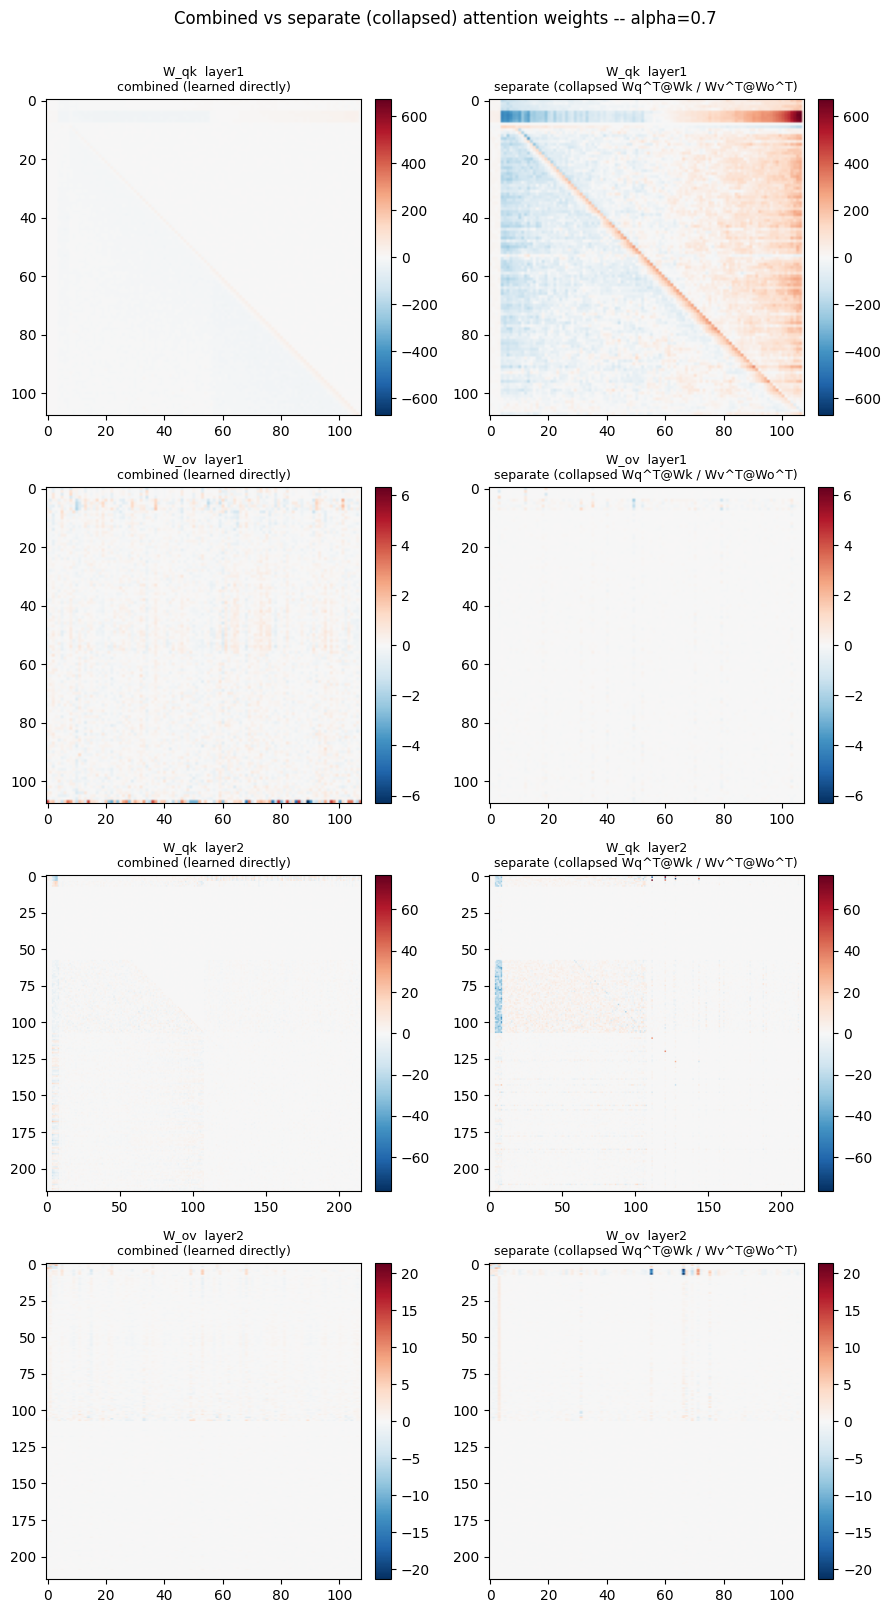

In [8]:
# ── EDIT HERE ──────────────────────────────────────────────────────────────
PLOT_THR = cmp_thrs[len(cmp_thrs) // 2]   # which threshold's matrices to visualize
# ─────────────────────────────────────────────────────────────────────────

m_comb_p, _ = load_trained_model(PLOT_THR, MODELS_DIR_COMBINED)
m_sep_p,  _ = load_trained_model(PLOT_THR, MODELS_DIR_SEPARATE)
qk1_sep_p, ov1_sep_p = _collapse_separate(m_sep_p.layer1)
qk2_sep_p, ov2_sep_p = _collapse_separate(m_sep_p.layer2)

mats = [
    ('W_qk  layer1', m_comb_p.layer1.W_qk.data.cpu().numpy(), qk1_sep_p.cpu().numpy()),
    ('W_ov  layer1', m_comb_p.layer1.W_ov.data.cpu().numpy(), ov1_sep_p.cpu().numpy()),
    ('W_qk  layer2', m_comb_p.layer2.W_qk.data.cpu().numpy(), qk2_sep_p.cpu().numpy()),
    ('W_ov  layer2', m_comb_p.layer2.W_ov.data.cpu().numpy(), ov2_sep_p.cpu().numpy()),
]

fig, axes = plt.subplots(4, 2, figsize=(9, 16))
for row, (name, comb_mat, sep_mat) in enumerate(mats):
    vmax = max(np.abs(comb_mat).max(), np.abs(sep_mat).max(), 1e-12)
    for col, (label, mat) in enumerate([('combined (learned directly)', comb_mat),
                                         ('separate (collapsed Wq^T@Wk / Wv^T@Wo^T)', sep_mat)]):
        ax = axes[row, col]
        im = ax.imshow(mat, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
        ax.set_title(f'{name}\n{label}', fontsize=9)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(f'Combined vs separate (collapsed) attention weights -- alpha={PLOT_THR}', y=1.005)
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, f'combined_vs_separate_weights_x_{PLOT_THR}.png'),
            dpi=130, bbox_inches='tight')
plt.show()


## Notes for extending this

- **Compare SGD vs Adam**: set `OPTIMIZER='sgd'` in CONFIG and re-run from the training-infra cell
  down — checkpoints are tagged `simplified_{OPTIMIZER}` so both runs coexist on disk.
- **Compare frozen vs trainable FFN**: set `FREEZE_READOUT=False` and add `'ffn'` to `TRAIN_PARAMS`
  to get the fully-joint baseline (closer to folders 6/10's setting, just at the reduced size).
- **If the trained curve doesn't approach context-Bayes**: check the frozen-readout fit-quality
  plot first (mean/max abs error) — a loose fit caps how close GD can get even with perfect
  attention. Raise `FREEZE_HIDDEN_K` / `FREEZE_FIT_STEPS` if needed.
- **Everything is reproducible from CONFIG alone** — no cell here depends on a previous run's
  in-memory state beyond `results` (built fresh each full run) and the frozen-fit cache (re-fit
  each time `build_frozen_ffn` is called, deterministic given `FREEZE_DELTA/K/FMAX/STEPS`).
